In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

8.1


In [67]:
df = pd.read_csv('diabetes.csv')

print(df.shape)
print(df.head())
print(df.columns)

(768, 9)
   Pregnancies  Glucose  BloodPressure  ...  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72  ...                     0.627   50        1
1            1       85             66  ...                     0.351   31        0
2            8      183             64  ...                     0.672   32        1
3            1       89             66  ...                     0.167   21        0
4            0      137             40  ...                     2.288   33        1

[5 rows x 9 columns]
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


In [68]:
X = df.drop(columns='Outcome')
y = df['Outcome']

print(X.shape)
print(y.shape)

(768, 8)
(768,)


In [69]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(np.mean(X_scaled, axis = 0))
print(np.std(X_scaled, axis = 0))


[-6.47630098e-17 -9.25185854e-18  1.50342701e-17  1.00613962e-16
 -3.00685403e-17  2.59052039e-16  2.45174251e-16  1.93132547e-16]
[1. 1. 1. 1. 1. 1. 1. 1.]


PCA

In [70]:
pca2 = PCA(n_components = 2)
X_pca2 = pca2.fit_transform(X_scaled)

print("Original Dimensions:", X_scaled.shape)
print("Reduced Dimensions:", X_pca2.shape)
print("PC1 Explained Varience Ratio:" , pca2.explained_variance_ratio_[0])
print("PC2 Explained Varience Ratio:" , pca2.explained_variance_ratio_[1])
print("Total Explained Varience Ratio:", sum(pca2.explained_variance_ratio_))

Original Dimensions: (768, 8)
Reduced Dimensions: (768, 2)
PC1 Explained Varience Ratio: 0.2617974931611007
PC2 Explained Varience Ratio: 0.21640126757746508
Total Explained Varience Ratio: 0.47819876073856576


8.2

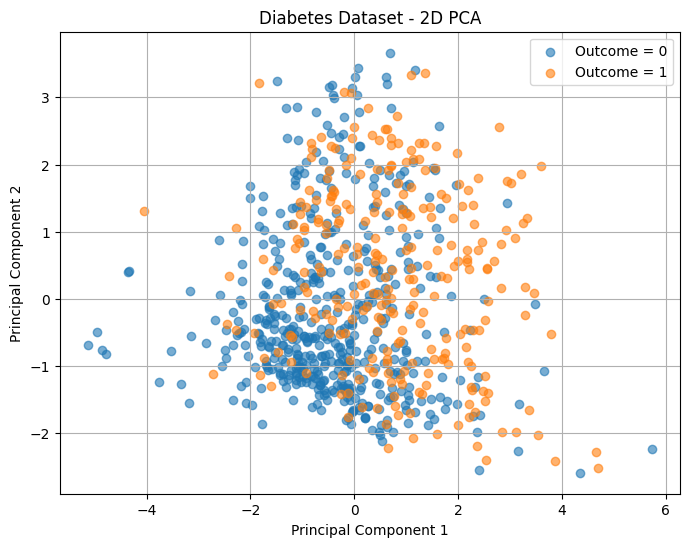

In [71]:
plt.figure(figsize = (8, 6))

plt.scatter(X_pca2[y == 0, 0], X_pca2[y == 0, 1], label = "Outcome = 0", alpha = 0.6)

plt.scatter(X_pca2[y == 1, 0], X_pca2[y == 1, 1], label = "Outcome = 1", alpha = 0.6)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Diabetes Dataset - 2D PCA")
plt.legend()
plt.grid(True)
plt.show()


8.3

In [72]:
pca3 = PCA(n_components = 3)
X_pca3 = pca3.fit_transform(X_scaled)

print("Original Dimensions:", X_scaled.shape)
print("Reduced Dimensions:", X_pca3.shape)

for i in range(3):
    print(f"PC{i+1} Explained Varience Ratio", pca3.explained_variance_ratio_[i])

print("Total Explained Varience Ratio:", sum(pca3.explained_variance_ratio_))

Original Dimensions: (768, 8)
Reduced Dimensions: (768, 3)
PC1 Explained Varience Ratio 0.2617974931611007
PC2 Explained Varience Ratio 0.21640126757746508
PC3 Explained Varience Ratio 0.12870373364801915
Total Explained Varience Ratio: 0.606902494386585


8.4

<function matplotlib.pyplot.show(close=None, block=None)>

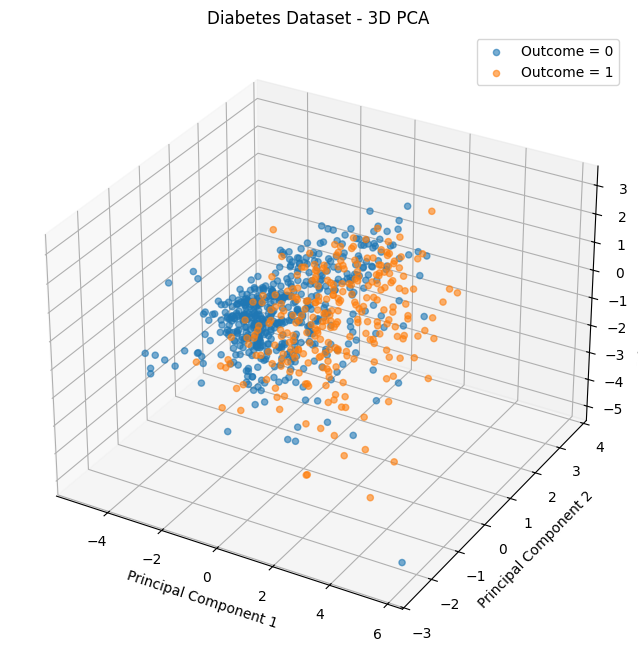

In [73]:
fig = plt.figure(figsize = (10, 8))
ax = fig.add_subplot(111, projection = '3d')

for outcome in [0, 1]:
  ax.scatter(X_pca3[y == outcome, 0], X_pca3[y == outcome, 1], X_pca3[y == outcome, 2], label = f"Outcome = {outcome}", alpha = 0.6)

ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_zlabel("Principal Component 3")
ax.set_title("Diabetes Dataset - 3D PCA")
ax.legend()

plt.show

Problem 9

9.1

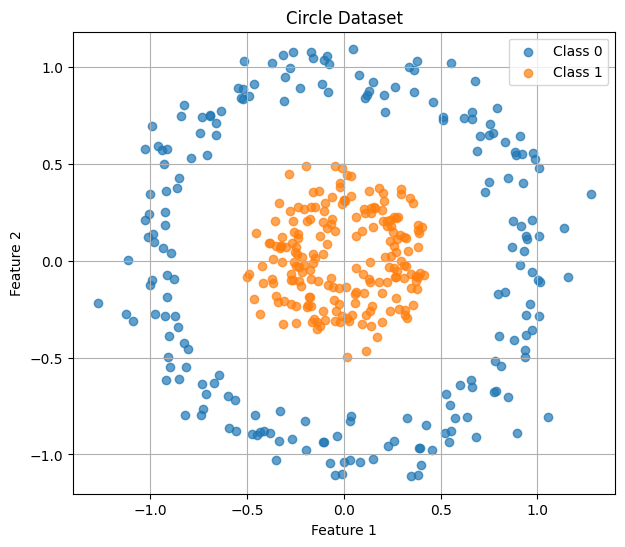

In [74]:
from sklearn.datasets import make_circles
from sklearn.svm import SVC

X, y = make_circles(n_samples = 400, noise = 0.1, factor = 0.3, random_state = 1)

plt.figure(figsize = (7,6))

plt.scatter(X[y == 0, 0], X[y == 0, 1], label = "Class 0", alpha = 0.7)

plt.scatter(X[y == 1, 0], X[y == 1, 1], label = "Class 1", alpha = 0.7)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Circle Dataset")
plt.legend()
plt.axis("equal")
plt.grid(True)
plt.show()

9.2

In [75]:
linearSVM = SVC(kernel = 'linear')
linearSVM.fit(X, y)

accuracy = linearSVM.score(X, y)
print("Accuracy:", accuracy)

Accuracy: 0.6725


In [76]:
def PlotDecisionBoundary(model, X, y, title):
  xMin, xMax = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
  yMin, yMax = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2

  xx, yy = np.meshgrid(np.linspace(xMin, xMax, 300), np.linspace(yMin, yMax, 300))

  Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
  Z = Z.reshape(xx.shape)

  plt.figure(figsize = (7, 6))
  plt.contourf(xx, yy, Z, levels = [-np.inf, 0, np.inf], alpha = 0.15)

  plt.contour(xx, yy, Z, levels = [0], colors = "black")

  for i in [0, 1]:
    plt.scatter(X[y == i, 0], X[y == i, 1], label = f"Class {i}", alpha = 0.7)

  plt.xlabel("Feature 1")
  plt.ylabel("Feature 2")
  plt.title(title)
  plt.legend()
  plt.axis("equal")
  plt.grid(True)
  plt.show()

/usr/local/lib/python3.13/dist-packages/matplotlib/colors.py:2293: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin
/usr/local/lib/python3.13/dist-packages/matplotlib/colors.py:2294: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)


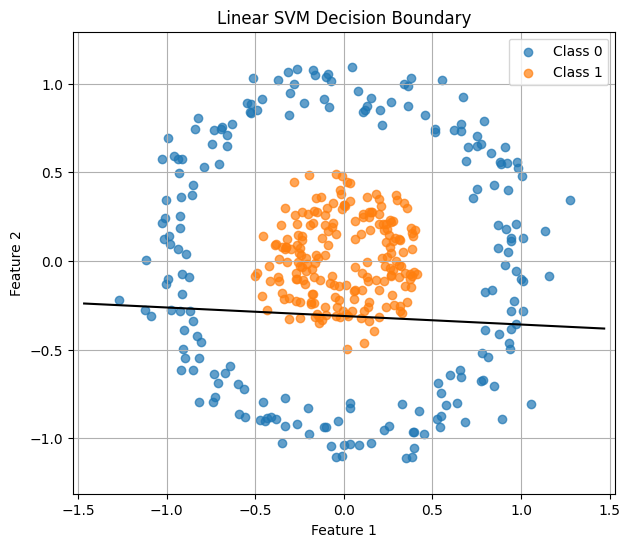

In [77]:
PlotDecisionBoundary(linearSVM, X, y, "Linear SVM Decision Boundary")

9.3

In [78]:
rbfSVM = SVC(kernel="rbf", gamma = 1.0)
rbfSVM.fit(X, y)

accuracy = rbfSVM.score(X, y)
print("Accuracy:", accuracy)

Accuracy: 1.0


/usr/local/lib/python3.13/dist-packages/matplotlib/colors.py:2293: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin
/usr/local/lib/python3.13/dist-packages/matplotlib/colors.py:2294: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)


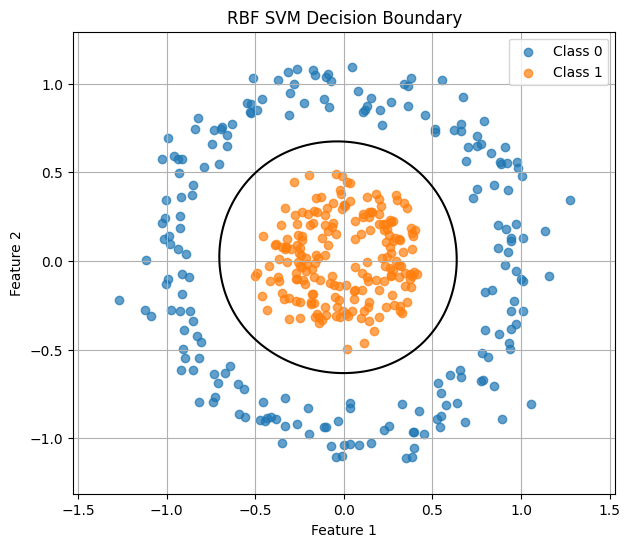

In [79]:
PlotDecisionBoundary(rbfSVM, X, y, "RBF SVM Decision Boundary")

9.4

Accuracy: 1.0


/usr/local/lib/python3.13/dist-packages/matplotlib/colors.py:2293: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin
/usr/local/lib/python3.13/dist-packages/matplotlib/colors.py:2294: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)


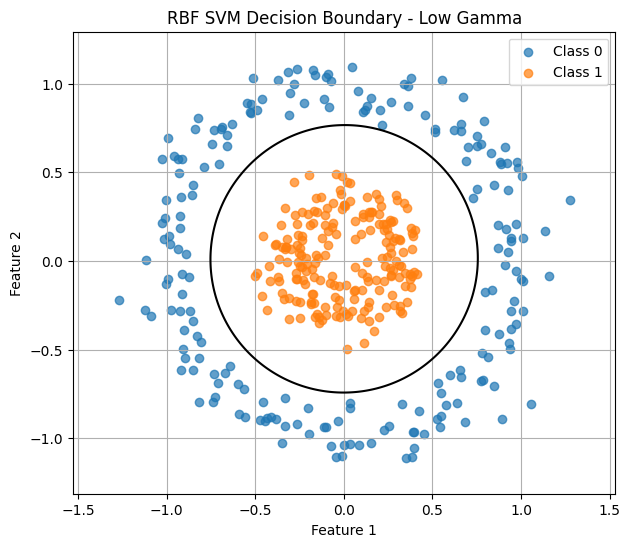

In [80]:
# Low Gamma
rbfSVM_low = SVC(kernel="rbf", gamma = 0.1)
rbfSVM_low.fit(X, y)


print("Accuracy:", rbfSVM_low.score(X, y))
PlotDecisionBoundary(rbfSVM_low, X, y, "RBF SVM Decision Boundary - Low Gamma")

Accuracy: 1.0


/usr/local/lib/python3.13/dist-packages/matplotlib/colors.py:2293: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin
/usr/local/lib/python3.13/dist-packages/matplotlib/colors.py:2294: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)


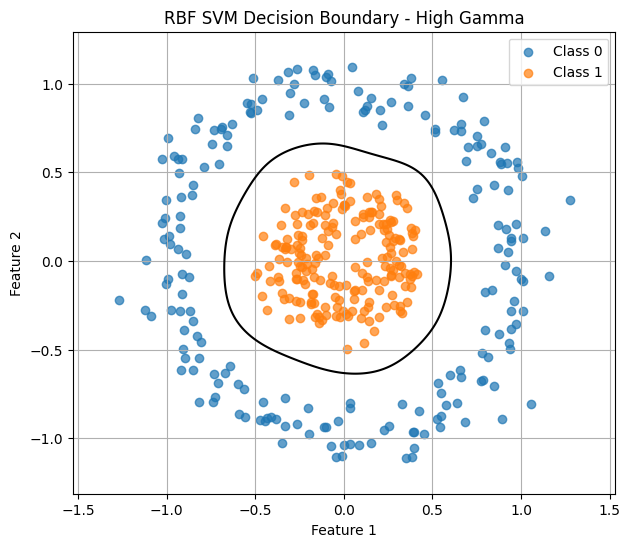

In [81]:
# High gamma
rbfSVM_high = SVC(kernel="rbf", gamma = 10)
rbfSVM_high.fit(X, y)


print("Accuracy:", rbfSVM_high.score(X, y))
PlotDecisionBoundary(rbfSVM_high, X, y, "RBF SVM Decision Boundary - High Gamma")

Problem 10

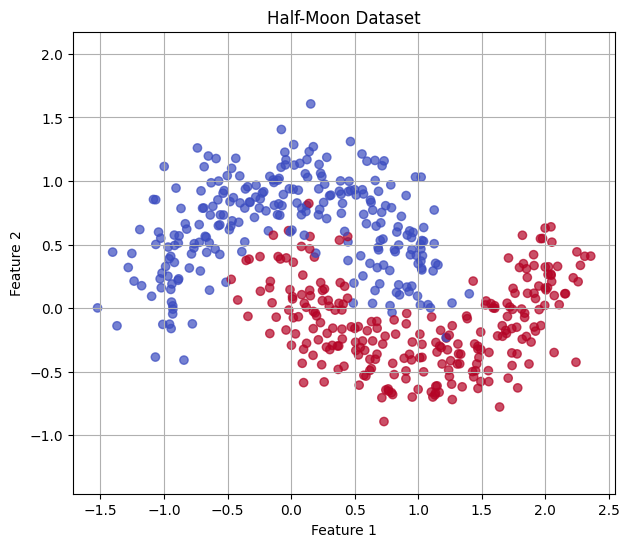

In [82]:
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans

X_moons, y_moons = make_moons(n_samples = 500, noise = 0.2, random_state = 1)

plt.figure(figsize = (7, 6))

plt.scatter(X_moons[:, 0], X_moons[:, 1], c = y_moons, cmap = "coolwarm", alpha = 0.7)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Half-Moon Dataset")
plt.axis("equal")
plt.grid(True)
plt.show()

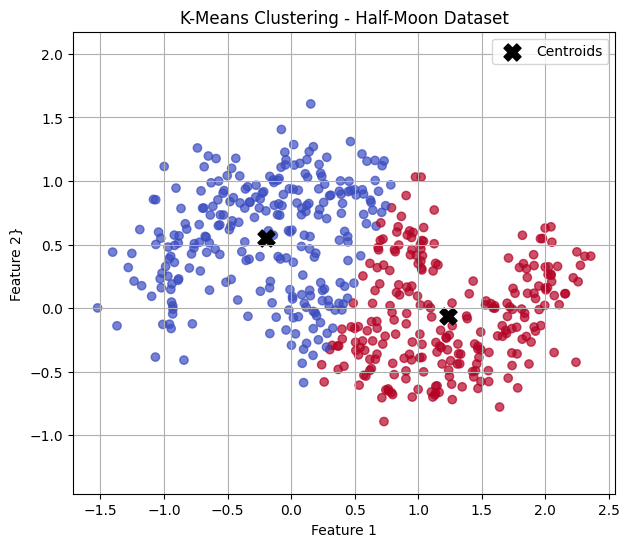

In [83]:
kmeans = KMeans(n_clusters = 2, random_state = 1, n_init = 10)
y_pred = kmeans.fit_predict(X_moons)

plt.figure(figsize = (7, 6))

plt.scatter(X_moons[:, 0], X_moons[:, 1], c = y_pred, cmap = "coolwarm", alpha = 0.7)

plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="black", marker="X" , s= 150, label = "Centroids")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2}")
plt.title("K-Means Clustering - Half-Moon Dataset")
plt.legend()
plt.axis("equal")
plt.grid(True)
plt.show()


evaluation metrics

In [84]:
from sklearn.metrics import adjusted_rand_score, v_measure_score, silhouette_score, calinski_harabasz_score

ARI = adjusted_rand_score(y_moons, y_pred)
print("Adjusted Rand Index:", ARI)

VM = v_measure_score(y_moons, y_pred)
print("V-Measure:", VM)

SS = silhouette_score(X_moons, y_pred)
print("Silhouette Score:", SS)

CH = calinski_harabasz_score(X_moons, y_pred)
print("Calinski-Harabasz Index:", CH)



Adjusted Rand Index: 0.23661505162596438
V-Measure: 0.1795171610685279
Silhouette Score: 0.46364554247990114
Calinski-Harabasz Index: 661.8710108210325


Problem 11


11.1

In [85]:
import torch
import torch.nn as nn
import torch.optim as optim

In [86]:
X_diabetes = df.drop(columns = 'Outcome')
y_diabetes = df['Outcome']

scaler = StandardScaler()
X_diabetes_scaled = scaler.fit_transform(X_diabetes)

X_tensor = torch.tensor(X_diabetes_scaled, dtype = torch.float32)

Y_tensor = torch.tensor(y_diabetes.values, dtype = torch.float32).view(-1, 1)

print("Input Tensor Shape", X_tensor.shape)
print("Output Tensor Shape", Y_tensor.shape)

Input Tensor Shape torch.Size([768, 8])
Output Tensor Shape torch.Size([768, 1])


11.2

In [87]:
class TorchNet(nn.Module):
  def __init__(self, inputDim, outputDim):
    super().__init__()

    self.layer1 = nn.Linear(inputDim, 4)
    self.layer2 = nn.Linear(4, 3)
    self.layer3 = nn.Linear(3, outputDim)

    self.relu = nn.ReLU()
    self.sigmoid = nn.Sigmoid()

  def forward(self, x):
    x = self.relu(self.layer1(x))
    x = self.relu(self.layer2(x))
    x = self.sigmoid(self.layer3(x))

    return x

In [88]:
torch.manual_seed(1)

model = TorchNet(inputDim = 8, outputDim = 1)

print(model)

predictions = model(X_tensor)

print("Prediction Shape:", predictions.shape)

TorchNet(
  (layer1): Linear(in_features=8, out_features=4, bias=True)
  (layer2): Linear(in_features=4, out_features=3, bias=True)
  (layer3): Linear(in_features=3, out_features=1, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
)
Prediction Shape: torch.Size([768, 1])


11.3

In [89]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr = 0.01)

epochs = 1000
lossHistory = []

In [90]:
model.train()

for epoch in range(epochs):
  # Forward propagation
  predictions = model(X_tensor)

  # loss
  loss = criterion(predictions, Y_tensor)

  # reset gradients
  optimizer.zero_grad()

  # Backward propagation
  loss.backward()

  # Update weights
  optimizer.step()

  # store loss
  lossHistory.append(loss.item())

  if (epoch + 1) % 100 == 0:
    print(f"Epoch [{epoch + 1}/{epochs}], Loss: {loss.item():.4f}")

Epoch [100/1000], Loss: 0.4773
Epoch [200/1000], Loss: 0.4544
Epoch [300/1000], Loss: 0.4464
Epoch [400/1000], Loss: 0.4385
Epoch [500/1000], Loss: 0.4345
Epoch [600/1000], Loss: 0.4335
Epoch [700/1000], Loss: 0.4273
Epoch [800/1000], Loss: 0.4267
Epoch [900/1000], Loss: 0.4264
Epoch [1000/1000], Loss: 0.4265


11.4

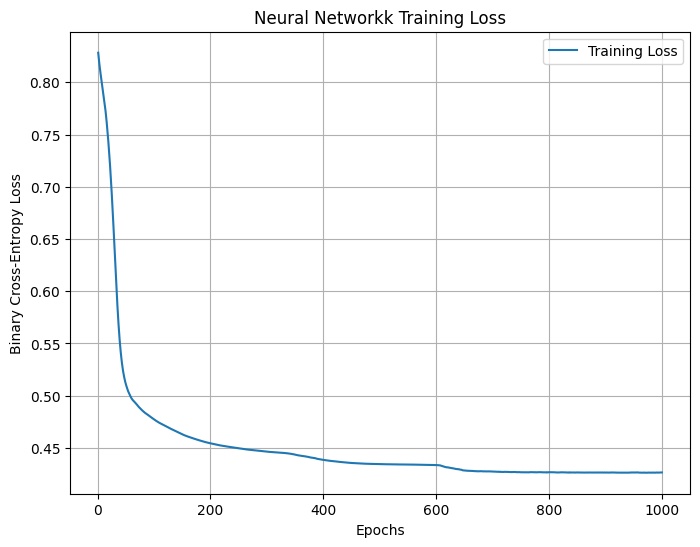

In [91]:
plt.figure(figsize = (8,6))

plt.plot(range(1, epochs + 1), lossHistory, label = "Training Loss")

plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Neural Networkk Training Loss")
plt.legend()
plt.grid(True)
plt.show()

11.5

In [92]:
!pip install -q onnx onnxruntime onnxscript

In [93]:
model.eval()

dummyInput = torch.zeros(1, 8, dtype = torch.float32)

torch.onnx.export(model,
                  dummyInput,
                  "TorchNet.onnx",
                  input_names = ["input"],
                  output_names = ["output"],
                  opset_version = 17,
                  dynamo = False)

print("Model saved successfully!")

Model saved successfully!


/tmp/ipykernel_900/2942466150.py:5: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model,


In [94]:
import onnx

onnxModel = onnx.load("TorchNet.onnx")
onnx.checker.check_model(onnxModel)

print("ONNX model verified")

ONNX model verified


11.6

In [95]:
patient = pd.DataFrame(
    [[7, 149, 73, 94, 94, 32, 0.672, 45]],
    columns = X_diabetes.columns
)

patientScaled = scaler.transform(patient)
patientScaled = patientScaled.astype(np.float32)

In [96]:
import onnxruntime as ort

session = ort.InferenceSession(
    "TorchNet.onnx",
    providers = ["CPUExecutionProvider"]
)

In [97]:
results = session.run(
    ["output"],
    {"input": patientScaled}
)

probability = results[0][0, 0]
prediction = int(probability >= 0.5)

print(f"Predicted Probability: {probability:.4f}")
print(f"Predicted Outcome: {prediction}")

Predicted Probability: 0.1635
Predicted Outcome: 0
